In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv('ushape.csv')

In [10]:
df.head()

,x,y,class
0,2.115098,-0.046244,1.0
1,0.882490,-0.075756,0.0
2,-0.055144,-0.037332,1.0
3,0.829545,-0.539321,1.0
4,2.112857,0.662084,1.0


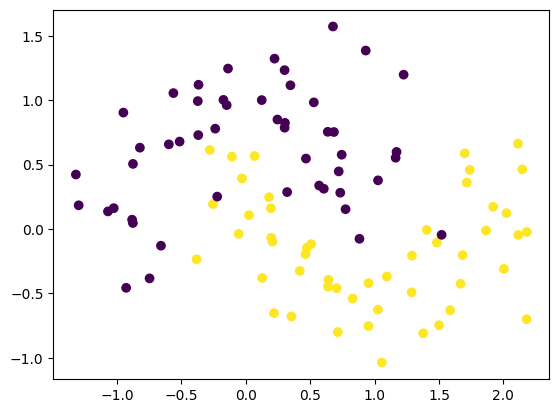

In [11]:
plt.scatter(df['x'],df['y'],c=df['class'])

In [12]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [13]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [14]:
model = Sequential()

model.add(Dense(10,activation='tanh',input_dim=2,kernel_initializer='glorot_normal'))
model.add(Dense(10,activation='tanh',kernel_initializer='glorot_normal'))
model.add(Dense(10,activation='tanh',kernel_initializer='glorot_normal'))
model.add(Dense(10,activation='tanh',kernel_initializer='glorot_normal'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.get_weights()

[array([[-0.07204218,  0.6376083 ,  0.47999808,  0.82430875, -0.69608986,
         -0.11020119,  0.41915464, -0.34847715,  0.0561849 , -0.3303314 ],
        [-0.7846008 , -0.07361189, -0.68361354, -0.40567043, -0.21263073,
          0.46863207,  0.23019703,  0.02367556, -0.04929529, -0.09845468]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.32089838, -0.45234305,  0.02163059,  0.07950673, -0.15521389,
         -0.5012304 ,  0.21267302,  0.16741739, -0.03325493, -0.07225573],
        [-0.17498934, -0.24378204, -0.15096718,  0.352056  , -0.45445448,
         -0.24821559, -0.02578973, -0.36494797,  0.18379828, -0.17651011],
        [-0.00648788,  0.5971367 ,  0.6519301 , -0.14042966,  0.03800644,
         -0.12687406, -0.23557372, -0.31860772,  0.32051393,  0.07285484],
        [ 0.05346208, -0.07069772,  0.46422508, -0.37434617,  0.33622643,
         -0.06489915,  0.32534593, -0.06195365, -0.466286  ,  0.01013063],
        [-0.69414

In [16]:
initial_weights = model.get_weights()

In [17]:
initial_weights[0] = np.random.randn(2,10)*np.sqrt(1/2)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(1/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [18]:
model.set_weights(initial_weights)

In [19]:
model.get_weights()

[array([[-0.72342664, -0.34238362,  0.29854503, -0.7954283 ,  0.50415605,
         -1.1462814 , -0.8875961 ,  0.05140427, -0.3315151 ,  1.2948347 ],
        [-0.09844705,  1.5951961 ,  0.04740552, -0.33563992,  1.911309  ,
          0.86092263, -0.8981521 , -0.11549546, -0.6319521 , -0.810013  ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.46134353,  0.12487142, -0.18843247, -0.03903447,  0.08985418,
          0.24442896,  0.5111428 , -0.2564262 ,  0.05080482, -0.52465224],
        [-0.14394078,  0.01230953, -0.3760708 , -0.32507938,  0.29807642,
         -0.34670645,  0.4874364 ,  0.7519289 , -0.51610327,  0.04957994],
        [-0.00866832,  0.11914214,  0.1909159 , -0.07067356,  0.48327082,
          0.06271034,  0.42713913, -0.2249957 , -0.06345022, -0.12011443],
        [-0.27434006, -0.26491943, -0.02324045, -0.27578932,  0.08673583,
          0.04253655,  0.43339273,  0.09599729, -0.46108097,  0.25623018],
        [ 0.18430

In [20]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [21]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 171ms/step - accuracy: 0.7468 - loss: 0.6562 - val_accuracy: 0.8000 - val_loss: 0.6376
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8354 - loss: 0.6416 - val_accuracy: 0.8000 - val_loss: 0.6204
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.8354 - loss: 0.6278 - val_accuracy: 0.8500 - val_loss: 0.6048
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8481 - loss: 0.6158 - val_accuracy: 0.9000 - val_loss: 0.5890
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8481 - loss: 0.6039 - val_accuracy: 0.9000 - val_loss: 0.5739
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8608 - loss: 0.5919 - val_accuracy: 0.9000 - val_loss: 0.5592
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.8608 - loss: 0.5809 - val_accuracy: 0.8500 - val_loss: 0.5450
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8608 - loss: 0.5709 - val_accuracy: 0.8500 - val_loss

In [22]:
model.get_weights()

[array([[-0.6427783 , -0.46657187,  0.21453036, -0.6203983 ,  0.43516782,
         -0.9921039 , -0.9310889 , -0.07213014, -0.39518407,  1.0584137 ],
        [ 0.03957448,  1.6056069 ,  0.10887934, -0.21116795,  1.9323293 ,
          1.0165924 , -0.962476  , -0.15957397, -0.5580738 , -0.9631706 ]],
       dtype=float32),
 array([ 0.01062611,  0.06775125, -0.0508852 , -0.0251489 , -0.01767121,
         0.06363805,  0.1583351 , -0.02339947,  0.28181762, -0.07864807],
       dtype=float32),
 array([[-0.532908  ,  0.2226861 , -0.12590373, -0.10761474,  0.16985808,
          0.15253064,  0.4565489 , -0.30509853,  0.0523385 , -0.5479804 ],
        [-0.2601435 ,  0.11564083, -0.45181888, -0.38454613,  0.2992389 ,
         -0.40967625,  0.4839636 ,  0.6973753 , -0.6185164 , -0.04843889],
        [ 0.10003681, -0.00807001,  0.17526765,  0.04409901,  0.36171737,
          0.17193384,  0.4515557 , -0.18257438, -0.03669229, -0.03493262],
        [-0.32850027, -0.17317143,  0.05349375, -0.3417461 , 

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step


<Axes: >

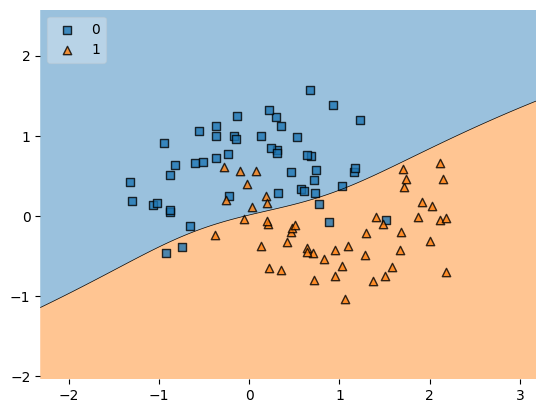

In [23]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X,y.astype('int'), clf=model, legend=2)

In [ ]:
(np.random.randn(10,10)*0.01).min()

np.float64(-0.02181910359574267)

In [25]:
(np.random.randn(10,10)*0.01).max()

np.float64(0.03197030934063629)